In [1]:
import sys
sys.path.append("..")

import json
import torch
import matplotlib.pyplot as plt
from src.data import load_mnist
from src.model import CNN
from src.client import local_train
from src.evaluate import evaluate

torch.manual_seed(0)
train, test = load_mnist()

In [2]:
model = CNN()
n_epochs = 20
accs = []

for e in range(n_epochs):
    state, _ = local_train(model, train, epochs=1)  
    model.load_state_dict(state)
    acc = evaluate(model, test)
    accs.append(acc)
    print(f"époque {e + 1} : {acc:.4f}")

époque 1 : 0.9285


époque 2 : 0.9624


époque 3 : 0.9739


époque 4 : 0.9723


époque 5 : 0.9797


...

époque 16 : 0.9864


époque 17 : 0.9871


époque 18 : 0.9882


époque 19 : 0.9873


époque 20 : 0.9885


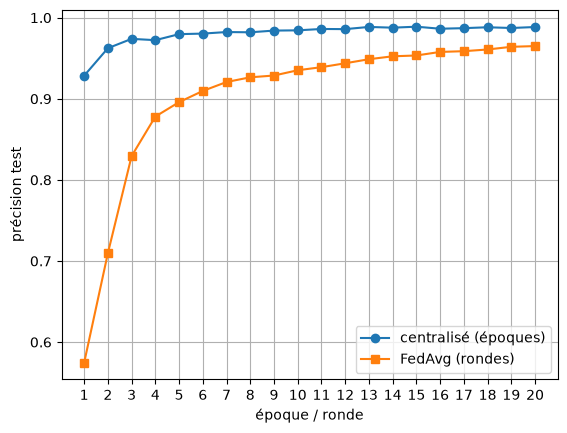

In [3]:
with open("../results/fedavg_iid.json") as f:
    fed = json.load(f)

x = range(1, n_epochs + 1)
plt.plot(x, accs, marker="o", label="centralisé (époques)")
plt.plot(range(1, len(fed) + 1), fed, marker="s", label="FedAvg (rondes)")
plt.xlabel("époque / ronde")
plt.ylabel("précision test")
plt.xticks(x)
plt.legend()
plt.grid(True)
plt.savefig("../results/centralise_vs_fedavg.png")
plt.show()